<hr style="border: 0; border-top: 4px solid #4a7fb5; margin: 28px 0 0">

# Worksheet 3 · Asking, Defining, Constraining, Deriving, Generating

*Advanced Methods of AI, WiSe 2026/2027 — the notebook of the tutorial.*

Last week you *represented* the pizza world in first-order logic and in Python. Today a service robot in a
pizzeria *uses* that knowledge. It does so with one kind of expression, a **description** written in the
Entity Query Language (EQL), and the evening shows five things it can do with one:

| Act | Story | The description is used as … | Logic |
|:--|:--|:--|:--|
| 1&nbsp;Asking | "Which pizzas have cheese?" "Bring me *the* one with olives." | a question | ∃, ∀, ¬ in one interpretation; *the* |
| 2&nbsp;Defining | "Which pizzas may carry the green V?" | a definition | necessary and sufficient conditions, classification |
| 3&nbsp;Constraining | "Ben must never get milk." | a constraint | ∀ checked as ¬∃¬ |
| 4&nbsp;Deriving | the kitchen writes allergen warnings | the body of a rule that creates objects | ∃ in the head, forward chaining |
| 5&nbsp;Generating | Dana orders a pizza that does not exist yet | a specification | constructing a model |

Acts 1 and 3 *read* the knowledge base; Acts 2, 4 and 5 *write* to it.

<div style="border-left: 5px solid #4a7fb5; background-color: rgba(74, 127, 181, 0.13); border-radius: 0 8px 8px 0; padding: 2px 20px; margin: 14px 0; line-height: 1.6">

**How to work.** Run the cells from top to bottom. Cells marked `TODO` are yours; every cell runs as it
is, so you can always go on. Every task names the language of its answer: **EQL** (a query),
**Python** (ordinary code on real objects) or **logic** (a formula, on the worksheet). Before a cell
marked **Predict**, write your prediction on the worksheet. Every answer is drawn as a picture of the
pizzeria, and the robot checks your answers: a green box when the answer is right, a red box with a hint
when it is not. A wrong answer costs the pizzeria a **fine**; the bill at the end adds them all up, across
restarts too. Compare your bill with your neighbours: the lowest wins.

</div>

## Setup

Run the next cell first. On a new machine it installs EQL (part of the library KRROOD) and the drawing
helpers `kitchen_picture.py` and `answer_check.py`. That takes one to two minutes; afterwards the cell does nothing.

In [1]:
import importlib.util, pathlib, subprocess, sys, urllib.request

SOURCE = "https://github.com/AbdelrhmanBassiouny/cognitive_robot_abstract_machine/archive/2ec20a0f732f8eb4f82df4a055b3ac4ecad0f8c5.zip"
WORKSHEET = "https://raw.githubusercontent.com/AbdelrhmanBassiouny/cognitive_robot_abstract_machine/claude/serene-carson-x3hvx6/exercises/advanced_methods_of_ai/wise26"


def install(*arguments):
    # Run pip in the Python of this notebook; show its output only if it fails.
    result = subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", *arguments],
                            capture_output=True, text=True)
    if result.returncode != 0:
        print(result.stdout, result.stderr)
        raise RuntimeError("The installation failed; see the output above.")


for helper in ("kitchen_picture.py", "answer_check.py", "requirements.txt"):
    if not pathlib.Path(helper).exists():
        urllib.request.urlretrieve(f"{WORKSHEET}/{helper}", helper)

if importlib.util.find_spec("krrood") is None:
    print("installing EQL, this takes one to two minutes ...")
    install("--no-deps", *(f"{package} @ {SOURCE}#subdirectory={package}"
                           for package in ("krrood", "random_events", "probabilistic_model")))
    install("-r", "requirements.txt")
print("ready")

ready


<hr style="border: 0; border-top: 4px solid #4a7fb5; margin: 28px 0 0">

## Prologue · The world the robot knows

The classes are those of `pizza.owl`, as in Worksheet 2. New are `Guest` and `Order`, because a pizzeria
needs to know who gets what. The four base classes inherit `Symbol`: every object of such a class is
entered in the robot's **registry** the moment it is created. **Run the next three cells; do not edit
them.**

In [2]:
from __future__ import annotations

import inspect
from dataclasses import dataclass, field
from enum import Enum

from IPython.display import SVG, display

from krrood.class_diagrams.class_diagram import ClassDiagram, HasRoleTaker

from krrood.entity_query_language.backends import (
    EntityQueryLanguageBackend, EntityQueryLanguageGenerativeBackend,
)
from krrood.entity_query_language.exceptions import MultipleSolutionFound, NoSolutionFound
from krrood.entity_query_language.factories import (
    a, an, the, every_is, none_is, entity, set_of,
    or_, not_, exists, for_all, HasType,
    inference, deduced_variable, add, refinement, alternative,
)
from krrood.entity_query_language.predicate import Predicate, symbolic_function
from krrood.entity_query_language.verbalization.vocabulary.english import Prepositions
from krrood.entity_query_language.verbalization.vocabulary.parts_of_speech import (
    Adjective, Copula, Noun, clause,
)
from krrood.patterns.role import Role
from krrood.symbol_graph.symbol_graph import Symbol

from answer_check import AnswerChecker, Task
from kitchen_picture import Colour, KitchenPicture, legend_svg

In [3]:
class Spiciness(Enum):
    MILD = 1
    MEDIUM = 2
    HOT = 3


class Allergen(Enum):
    # Three of the fourteen allergens a restaurant in the EU has to declare.
    GLUTEN = "gluten"
    MILK = "milk"
    FISH = "fish"


# ---- toppings: the class hierarchy of pizza.owl ----

@dataclass(eq=False, repr=False)
class PizzaTopping(Symbol):
    spiciness: Spiciness = Spiciness.MILD

    def __repr__(self):
        return type(self).__name__


class CheeseTopping(PizzaTopping): ...
class MozzarellaTopping(CheeseTopping): ...
class ParmesanTopping(CheeseTopping): ...

class VegetableTopping(PizzaTopping): ...
class TomatoTopping(VegetableTopping): ...
class OliveTopping(VegetableTopping): ...
class CaperTopping(VegetableTopping): ...
class MushroomTopping(VegetableTopping): ...

@dataclass(eq=False, repr=False)
class JalapenoPepperTopping(VegetableTopping):
    spiciness: Spiciness = Spiciness.HOT

@dataclass(eq=False, repr=False)
class HotGreenPepperTopping(VegetableTopping):
    spiciness: Spiciness = Spiciness.HOT

class MeatTopping(PizzaTopping): ...
class HamTopping(MeatTopping): ...

@dataclass(eq=False, repr=False)
class PeperoniSausageTopping(MeatTopping):
    spiciness: Spiciness = Spiciness.MEDIUM

class FishTopping(PizzaTopping): ...
class AnchoviesTopping(FishTopping): ...


# ---- pizzas ----

@dataclass(eq=False, repr=False)
class Pizza(Symbol):
    name: str = "a new pizza"
    toppings: list[PizzaTopping] = field(default_factory=list)

    def __repr__(self):
        return self.name


class Margherita(Pizza): ...
class Napoletana(Pizza): ...
class AmericanHot(Pizza): ...
class Mushroom(Pizza): ...


# ---- new this week: guests and orders ----

@dataclass(eq=False, repr=False)
class Guest(Symbol):
    name: str
    avoids: set[Allergen] = field(default_factory=set)

    def __repr__(self):
        return self.name


@dataclass(eq=False, repr=False)
class Order(Symbol):
    table: int
    guest: Guest
    pizzas: list[Pizza]

    def __repr__(self):
        return f"Order(table {self.table})"

In [4]:
# ---- the objects: what is true tonight ----

margherita_1 = Margherita("margherita_1", [MozzarellaTopping(), TomatoTopping()])
napoletana_1 = Napoletana("napoletana_1", [AnchoviesTopping(), CaperTopping(), MozzarellaTopping(),
                                           OliveTopping(), TomatoTopping()])
american_hot_1 = AmericanHot("american_hot_1", [HotGreenPepperTopping(), JalapenoPepperTopping(),
                                                MozzarellaTopping(), PeperoniSausageTopping(),
                                                TomatoTopping()])
mushroom_1 = Mushroom("mushroom_1", [MozzarellaTopping(), MushroomTopping(), TomatoTopping()])
veggie_1 = Pizza("veggie_1", [TomatoTopping(), OliveTopping(), MushroomTopping()])
plain_1 = Pizza("plain_1", [])                          # p3 of Worksheet 2: no toppings at all
unclosed_1 = Pizza("unclosed_1", [MozzarellaTopping()])  # UnclosedPizza of Worksheet 2, Task 3(c)

pizzas = [margherita_1, napoletana_1, american_hot_1, mushroom_1, veggie_1, plain_1, unclosed_1]

ada = Guest("Ada")
ben = Guest("Ben", avoids={Allergen.MILK})
chidi = Guest("Chidi", avoids={Allergen.FISH})
guests = [ada, ben, chidi]

orders = [
    Order(1, ada, [margherita_1, american_hot_1]),
    Order(2, ben, [veggie_1, napoletana_1]),
    Order(3, chidi, [mushroom_1]),
]


# ---- last week's function (solution of Worksheet 2, Task 3) ----

def is_vegetarian(pizza: Pizza) -> bool:
    return not any(isinstance(t, (MeatTopping, FishTopping)) for t in pizza.toppings)

The next cell defines how the robot shows its answers: `show` for a question, `refer` for a question
about *the* one object, `check` for a constraint. Given a `Task`, they also check the answer against the
solution. Run it; reading it is optional.

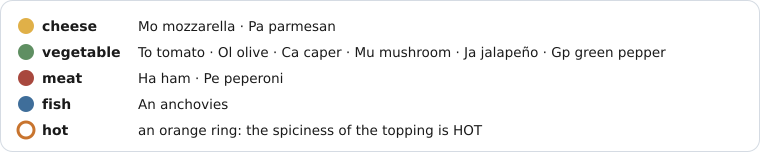

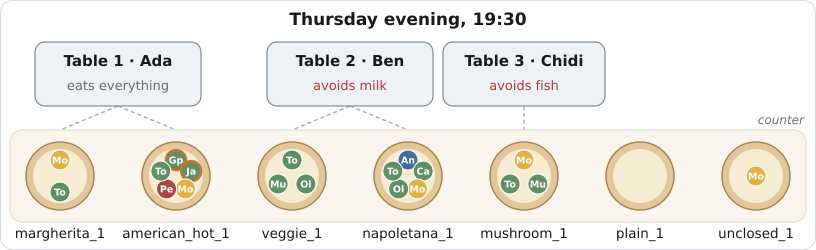

In [5]:
def picture(marked=(), violations=(), notes=(), warnings=(), title="", more_orders=(), more_pizzas=()):
    # Draw the pizzeria; ring the marked objects, draw violations in red, write notes below the pizzas.
    # more_pizzas are drawn after the counter as new pizzas, even if nothing rings them.
    kitchen = KitchenPicture(pizzas, orders + list(more_orders), marked=list(marked),
                             new_pizzas=list(more_pizzas), violations=list(violations), title=title)
    for pizza, text in notes:
        kitchen.note(pizza, text)
    for pizza, text in warnings:
        kitchen.note(pizza, text, Colour.WARNING)
    display(SVG(kitchen.to_svg()))


def rows_of(query):
    # The answers of a query, each as a tuple of the values of its selected variables.
    return [tuple(answer.values()) if isinstance(answer, dict) or hasattr(answer, "values") else (answer,)
            for answer in query.tolist()]


checker = AnswerChecker()


def grade(task, answers):
    # Compare the answers with the solution of the task: green if right, red with a hint and a fine if not.
    if task is not None:
        display(checker.check(task, None if answers is None else [str(answer) for answer in answers]))


def show(title, query, task=None):
    # A question: print every answer and ring it in the picture.
    if query is ...:
        print(f"{title}: TODO")
        grade(task, None)
        return
    rows = rows_of(query)
    print(f"{title}: {len(rows)} answer(s)")
    for row in rows:
        print("   ", row[0] if len(row) == 1 else row)
    picture(marked=[value for row in rows for value in row], title=title)
    grade(task, [", ".join(str(value) for value in row) for row in rows])


def refer(title, description, task=None):
    # A reference: the description must pick out exactly one object.
    if description is ...:
        print(f"{title}: TODO")
        grade(task, None)
        return
    try:
        [(referent,)] = rows_of(description)
    except NoSolutionFound:
        print(f"{title}: nothing fits. The description does not refer.")
        grade(task, [])
        return
    except MultipleSolutionFound:
        print(f"{title}: more than one object fits. The robot has to ask back.")
        if task is not None:
            display(checker.check_ambiguous(task))
        return
    print(f"{title}: {referent}")
    picture(marked=[referent], title=title)
    grade(task, [referent])


def check(title, constraint, task=None):
    # A constraint: every answer is a violation; the picture draws it in red.
    if constraint is ...:
        print(f"{title}: TODO")
        grade(task, None)
        return
    rows = rows_of(constraint)
    if not rows:
        print(f"{title}: satisfied, no answer")
    for row in rows:
        print(f"{title}: VIOLATED by", row)
    violations = [(order, pizza) for row in rows for order in row if isinstance(order, Order)
                  for pizza in row if isinstance(pizza, Pizza)]
    picture(violations=violations, title=title)
    grade(task, [", ".join(str(value) for value in row) for row in rows])


display(SVG(legend_svg()))
picture(title="Thursday evening, 19:30")

This picture *is* an interpretation in the sense of first-order logic. Its domain is the set of objects
(pizzas, toppings, guests, orders); the extension of the predicate `CheeseTopping` is the set of yellow
dots; the extension of the relation `hasTopping` is the set of pairs (pizza, dot on that pizza). Every
query today is evaluated *in* this one interpretation.

### EQL in one table

Keep this table at hand; it is also on page 3 of the worksheet.

| EQL | Read it as | First-order logic |
|:--|:--|:--|
| `a(Pizza)` | some object of class `Pizza` | a variable `x` with `Pizza(x)` |
| `a(Pizza)(toppings=a(CheeseTopping))` | a pizza with a cheese topping | `Pizza(x) ∧ ∃t (hasTopping(x, t) ∧ CheeseTopping(t))` |
| `toppings=every_is(VegetableTopping)` | … whose every topping is a vegetable | `∀t (hasTopping(x, t) → VegetableTopping(t))` |
| `toppings=none_is(CheeseTopping)` | … with no cheese topping | `¬∃t (hasTopping(x, t) ∧ CheeseTopping(t))` |
| <code>none_is(OliveTopping &#124; CaperTopping)</code> | … with no olive or caper topping | `¬∃t (hasTopping(x, t) ∧ (OliveTopping(t) ∨ CaperTopping(t)))` |
| `a(Pizza)(toppings=[A, B])` | a pizza whose topping list is exactly `[A, B]` | the whole list, in this order |
| `a(PizzaTopping)(spiciness=Spiciness.MILD)` | a topping whose spiciness is mild | `spiciness(t) = mild` |
| `a(Pizza)` without `.from_` | … among every pizza the robot knows | the domain is the registry |
| `.from_(pizzas)` | … among these objects only | the domain of `x` |
| `the(...)` | *the* … : exactly one fits | `∃x (φ(x) ∧ ∀y (φ(y) → y = x))` |
| `a(PizzaTopping).from_(pizza.toppings)` | a topping of that pizza, with a name | a variable `t` with `hasTopping(x, t)` |
| `pizza.where(pizza.toppings.spiciness == Spiciness.MILD)` | a pizza with a mild topping | `∃t (hasTopping(x, t) ∧ spiciness(t) = mild)` |
| `HasType(t, VegetableTopping)` | `t` is a vegetable topping | `VegetableTopping(t)` |
| `exists(t, φ)`, `for_all(t, φ)` | some / every `t` satisfies `φ` | `∃t φ`, `∀t φ` (over the toppings of `x`) |
| `not_(φ)`, `or_(φ, ψ)`, `.where(φ, ψ)` | not, or, and | `¬φ`, `φ ∨ ψ`, `φ ∧ ψ` |
| `set_of(x, t)` | return the pairs | the free variables of the formula |
| `.tolist()` | evaluate now | the set of satisfying assignments |

Writing a query computes nothing: it builds a symbolic expression. Only `.tolist()` (or iterating over
it) evaluates it. The helpers `show`, `refer` and `check` call `.tolist()` for you.

<hr style="border: 0; border-top: 4px solid #4a7fb5; margin: 28px 0 0">

## Act 1 · Asking: *"Which pizzas have cheese?"*

The chef needs to know which pizzas go back into the oven for a minute, so that the cheese melts.

### 1(a) A description is a formula with one free variable

`a(Pizza)(...)` describes an object by its attributes, `.from_(pizzas)` says where to look. Without a
pattern, `a(CheeseTopping)` describes any object of its class. A pattern given for the list `toppings`
describes *one element* of the list, so it means *some topping fits*.
Read the query aloud: *"a pizza with a cheese topping, from the pizzas"*.

cheesy pizzas: 5 answer(s)
    margherita_1
    napoletana_1
    american_hot_1
    mushroom_1
    unclosed_1


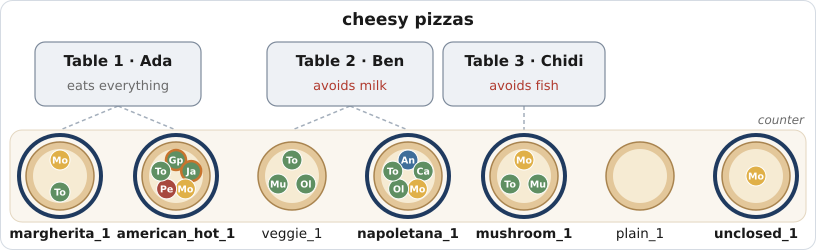

In [6]:
cheesy = a(Pizza)(toppings=a(CheeseTopping)).from_(pizzas)
show("cheesy pizzas", cheesy)

### 1(b) Some, only, none

`a(...)` in a pattern says *some topping is …*. `every_is(...)` and `none_is(...)` take its place to say *every
topping is …* and *no topping is …*. Each query below introduces its own variables, just as every formula
binds its own.

<div style="border-left: 5px solid #c38d2c; background-color: rgba(195, 141, 44, 0.14); border-radius: 0 8px 8px 0; padding: 2px 20px; margin: 14px 0; line-height: 1.6">

**Predict** on the worksheet which pizzas each query returns, then run the cell. Watch `plain_1` (no
toppings) and `unclosed_1` (only mozzarella).

</div>

Q1  every topping is a vegetable: 2 answer(s)
    veggie_1
    plain_1


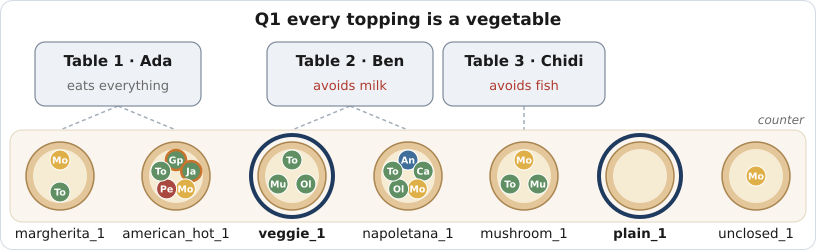

Q2  the toppings are [a mozzarella, a tomato]: 1 answer(s)
    margherita_1


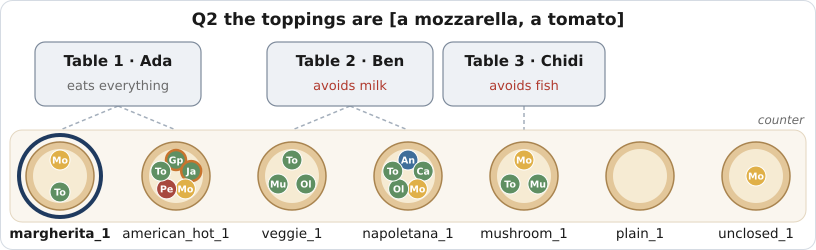

Q3  no topping is a cheese: 2 answer(s)
    veggie_1
    plain_1


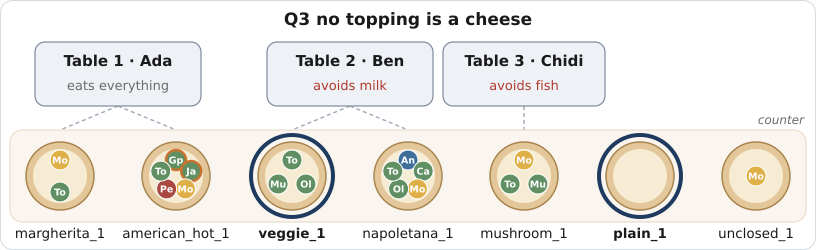

In [7]:
only_vegetables = a(Pizza)(toppings=every_is(VegetableTopping)).from_(pizzas)
show("Q1  every topping is a vegetable", only_vegetables)

exactly_these = a(Pizza)(toppings=[a(MozzarellaTopping), a(TomatoTopping)]).from_(pizzas)
show("Q2  the toppings are [a mozzarella, a tomato]", exactly_these)

no_cheese = a(Pizza)(toppings=none_is(CheeseTopping)).from_(pizzas)
show("Q3  no topping is a cheese", no_cheese)

<div style="border-left: 5px solid #8a97a8; background-color: rgba(138, 151, 168, 0.13); border-radius: 0 8px 8px 0; padding: 2px 20px; margin: 14px 0; line-height: 1.6">

**Solution note.**

- **Q1** returns `veggie_1` and `plain_1`. `∀t (hasTopping(x, t) → VegetableTopping(t))` is true for a
  pizza without toppings, because there is no counterexample (vacuous truth).
- **Q2** returns only `margherita_1`. A *list* of patterns describes the *whole* list: a mozzarella, then a
  tomato, nothing else. This implies the closure of Worksheet 2 (some mozzarella, some tomato, and only
  these), and is stronger: it also fixes the number and the order. `mushroom_1` has a third topping,
  `unclosed_1` only one.
- **Q3** returns `veggie_1` and `plain_1`. Nobody stated "veggie_1 has no cheese". The query concludes it
  because no cheese is in the list: the stored list is taken to be complete (closed-world assumption).

</div>

A pattern can also name several classes at once, written as for `isinstance`: `OliveTopping | CaperTopping`
is a topping that is an olive topping *or* a caper topping.

<div style="border-left: 5px solid #4a7fb5; background-color: rgba(74, 127, 181, 0.13); border-radius: 0 8px 8px 0; padding: 2px 20px; margin: 14px 0; line-height: 1.6">

**Your turn · EQL.** The menu marks the vegetarian pizzas. Write `vegetarian`: the pizzas with no meat
topping and no fish topping. Hint: *one* `none_is`.

</div>

vegetarian pizzas: 5 answer(s)
    margherita_1
    mushroom_1
    veggie_1
    plain_1
    unclosed_1


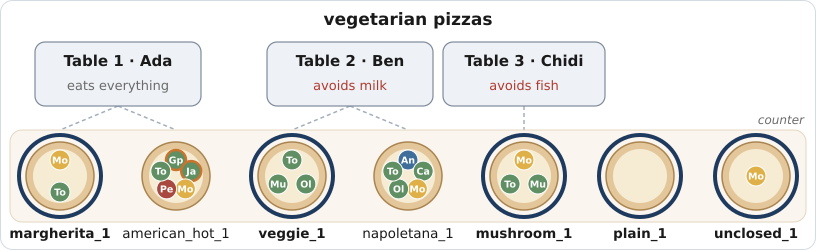

Correct! The green V is on exactly the right pizzas. The vegetarians at the bar order seconds.

In [8]:
vegetarian = a(Pizza)(toppings=none_is(MeatTopping | FishTopping)).from_(pizzas)
show("vegetarian pizzas", vegetarian, Task.VEGETARIAN_PIZZAS)

<div style="border-left: 5px solid #8a97a8; background-color: rgba(138, 151, 168, 0.13); border-radius: 0 8px 8px 0; padding: 2px 20px; margin: 14px 0; line-height: 1.6">

**Solution note.**

Five pizzas: `margherita_1`, `mushroom_1`, `veggie_1`, `plain_1`, `unclosed_1`. In logic:
`Pizza(x) ∧ ¬∃t (hasTopping(x, t) ∧ (MeatTopping(t) ∨ FishTopping(t)))`, equivalently
`∀t (hasTopping(x, t) → ¬MeatTopping(t) ∧ ¬FishTopping(t))`. `unclosed_1` is in, unlike last week in
Protégé: the query reads the list as complete, the OWL reasoner does not. The union puts the `∨` inside
the one quantifier; `toppings` takes one value, so two `none_is` patterns cannot both be given.

</div>

### 1(c) Following the relations

Ada at table 1 does not like spicy food: *"Is anything hot on my table?"* Patterns nest as deep as the
objects do: an order has pizzas, a pizza has toppings, a topping has a spiciness.

<div style="border-left: 5px solid #4a7fb5; background-color: rgba(74, 127, 181, 0.13); border-radius: 0 8px 8px 0; padding: 2px 20px; margin: 14px 0; line-height: 1.6">

**Your turn · EQL.** Write `hot_pizzas` (the pizzas with some topping whose spiciness is `Spiciness.HOT`) and
`hot_orders` (the orders with such a pizza). Use `an(Order)`: the query should read as English. This time
leave out `.from_`: the robot then searches its registry, which so far holds exactly tonight's objects.
A query is itself a description, so `hot_orders` can use `hot_pizzas`.

</div>

hot pizzas: 1 answer(s)
    american_hot_1


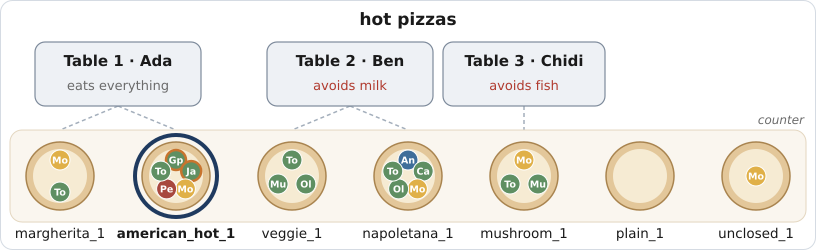

Correct! The robot warns Ada in time; she orders something mild and keeps her tongue.

orders with a hot pizza: 1 answer(s)
    Order(table 1)


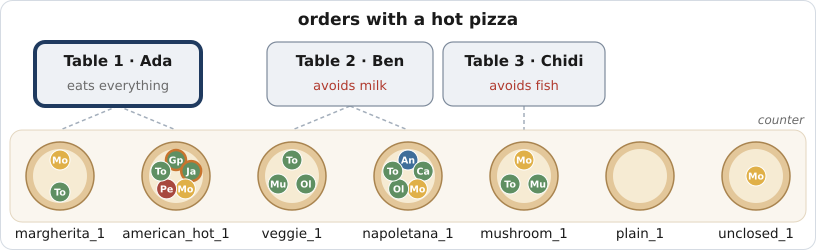

Correct! The right table is warned; nobody breathes fire tonight.

In [9]:
hot_pizzas = a(Pizza)(toppings=a(PizzaTopping)(spiciness=Spiciness.HOT))
hot_orders = an(Order)(pizzas=hot_pizzas)

show("hot pizzas", hot_pizzas, Task.HOT_PIZZAS)
show("orders with a hot pizza", hot_orders, Task.HOT_ORDERS)

<div style="border-left: 5px solid #8a97a8; background-color: rgba(138, 151, 168, 0.13); border-radius: 0 8px 8px 0; padding: 2px 20px; margin: 14px 0; line-height: 1.6">

**Solution note.**

`american_hot_1` and the order of table 1:
`Order(o) ∧ ∃x (hasPizza(o, x) ∧ ∃t (hasTopping(x, t) ∧ spiciness(t) = hot))`.
The American Hot has two hot toppings and is still returned once: `x` and `t` are bound by `∃`, only `o` is
free, and an object either satisfies the formula or it does not.

</div>

A **path** follows the relations as well. On the list `toppings`, an attribute that only its elements have
is read on an element: `pizza.toppings.spiciness` is the spiciness of *a topping* of the pizza. In
`.where(...)` it filters: the pizza is kept when one of its toppings passes, and returned once. Every
writing of the same path means the same topping.

<div style="border-left: 5px solid #c38d2c; background-color: rgba(195, 141, 44, 0.14); border-radius: 0 8px 8px 0; padding: 2px 20px; margin: 14px 0; line-height: 1.6">

**Predict** what the second query returns. Is it the pizzas with *no* hot topping? Watch `plain_1`.

</div>

a topping is hot: 1 answer(s)
    american_hot_1


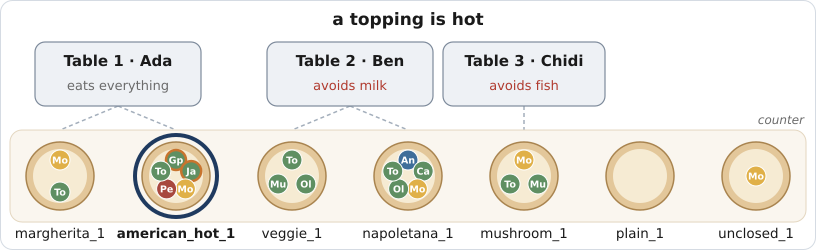

a topping is not hot: 7 answer(s)
    margherita_1
    napoletana_1
    american_hot_1
    mushroom_1
    veggie_1
    plain_1
    unclosed_1


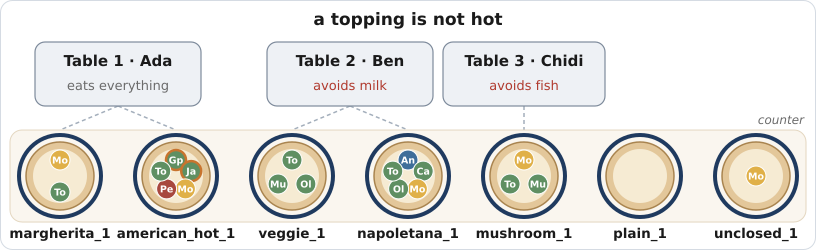

In [10]:
pizza = a(Pizza).from_(pizzas)
show("a topping is hot", pizza.where(pizza.toppings.spiciness == Spiciness.HOT))

pizza = a(Pizza).from_(pizzas)
show("a topping is not hot", pizza.where(not_(pizza.toppings.spiciness == Spiciness.HOT)))

<div style="border-left: 5px solid #8a97a8; background-color: rgba(138, 151, 168, 0.13); border-radius: 0 8px 8px 0; padding: 2px 20px; margin: 14px 0; line-height: 1.6">

**Solution note.**

The first query returns `american_hot_1`, like `hot_pizzas`. The second returns *every* pizza.
`not_` negates the condition on *the* topping the path names, so on a pizza with toppings it reads
`∃t (hasTopping(x, t) ∧ spiciness(t) ≠ hot)`: `american_hot_1` has a mozzarella, which is not hot.
`plain_1` has no topping at all: a condition on a topping that does not exist is false (closed world), so
its negation is true. *No hot topping* is `none_is`, as in 1(b):
`a(Pizza)(toppings=none_is(PizzaTopping)(spiciness=Spiciness.HOT))`.

</div>

Ada wants to know *what exactly* is hot. Now the robot does not ask *whether* there is a witness, it asks
for the witnesses themselves: the pizza and the topping become free variables, selected with `set_of`.
An answer is then a **binding**: one value per selected variable, such that the condition holds.

<div style="border-left: 5px solid #c38d2c; background-color: rgba(195, 141, 44, 0.14); border-radius: 0 8px 8px 0; padding: 2px 20px; margin: 14px 0; line-height: 1.6">

**Predict:** how many answers, and why not one?

</div>

who gets which hot topping: 2 answer(s)
    (Ada, american_hot_1, HotGreenPepperTopping)
    (Ada, american_hot_1, JalapenoPepperTopping)


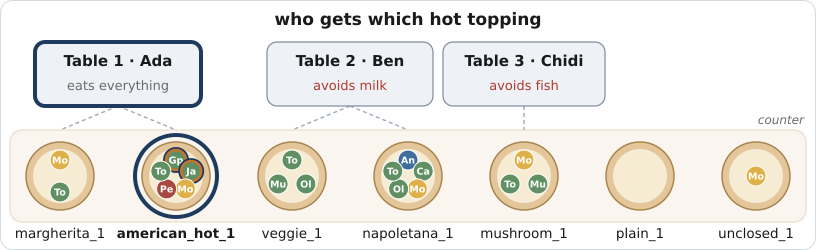

In [11]:
order = an(Order).from_(orders)
pizza = a(Pizza).from_(order.pizzas)                  # a pizza of that order
topping = a(PizzaTopping).from_(pizza.toppings)       # a topping of that pizza

what_is_hot = set_of(order.guest, pizza, topping).where(topping.spiciness == Spiciness.HOT)
show("who gets which hot topping", what_is_hot)

<div style="border-left: 5px solid #8a97a8; background-color: rgba(138, 151, 168, 0.13); border-radius: 0 8px 8px 0; padding: 2px 20px; margin: 14px 0; line-height: 1.6">

**Solution note.**

Two bindings: (Ada, american_hot_1, HotGreenPepperTopping) and (Ada, american_hot_1,
JalapenoPepperTopping). The formula `hasPizza(o, x) ∧ hasTopping(x, t) ∧ spiciness(t) = hot` with the
free variables `x` and `t` has two satisfying assignments. `hot_orders` hid `x` and `t` under `∃`, so it
had only one answer.

</div>

### 1(d) *a* or *the*?

Ben at table 2 waves: *"Bring me the pizza with olives."* A command does not name an object, it
describes one. `a(...)` accepts every object that fits; `the(...)` claims that *exactly one* fits and
raises an exception otherwise. It is still a question, with one more demand: on the number of answers.

<div style="border-left: 5px solid #c38d2c; background-color: rgba(195, 141, 44, 0.14); border-radius: 0 8px 8px 0; padding: 2px 20px; margin: 14px 0; line-height: 1.6">

**Predict** what the robot does for each command, then run the cell.

</div>

the pizza with ham: nothing fits. The description does not refer.
the pizza with fish: napoletana_1


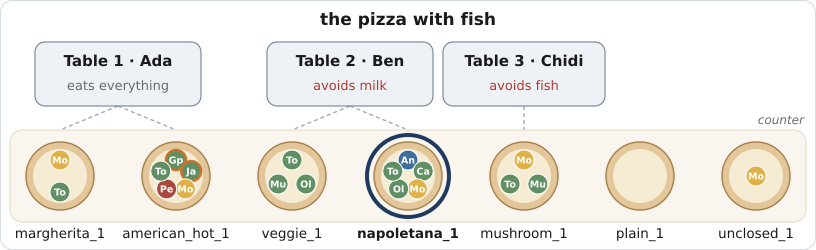

the pizza with olives: more than one object fits. The robot has to ask back.


In [12]:
refer("the pizza with ham", the(Pizza)(toppings=a(HamTopping)).from_(pizzas))
refer("the pizza with fish", the(Pizza)(toppings=a(FishTopping)).from_(pizzas))
refer("the pizza with olives", the(Pizza)(toppings=a(OliveTopping)).from_(pizzas))

<div style="border-left: 5px solid #8a97a8; background-color: rgba(138, 151, 168, 0.13); border-radius: 0 8px 8px 0; padding: 2px 20px; margin: 14px 0; line-height: 1.6">

**Solution note.**

Ham: no pizza fits (`NoSolutionFound`). Fish: `napoletana_1`. Olives: `napoletana_1` and `veggie_1`
(`MultipleSolutionFound`). Russell's analysis of *the F*: `∃x (F(x) ∧ ∀y (F(y) → y = x))`. When it
fails, Russell calls the sentence false; Strawson says it has no truth value, because its presupposition
fails. The robot, which refuses instead of answering, behaves like Strawson.

</div>

The robot asks back: *"The one with fish or the one without?"* Ben: *"Without fish."*

The pattern of `toppings` already names the olive, and an attribute takes one pattern. For a further
condition, give the topping a name, `topping = a(PizzaTopping).from_(pizza.toppings)`, and quantify over
it in `.where(...)` with `exists(topping, φ)` or `for_all(topping, φ)`. Q1 is then
`pizza.where(for_all(topping, HasType(topping, VegetableTopping)))`.

<div style="border-left: 5px solid #4a7fb5; background-color: rgba(74, 127, 181, 0.13); border-radius: 0 8px 8px 0; padding: 2px 20px; margin: 14px 0; line-height: 1.6">

**Your turn · EQL.** Start from *"the pizza with olives"* and add *"and no fish"* with `.where(...)`, so that
`the` succeeds.

</div>

the pizza with olives and without fish: veggie_1


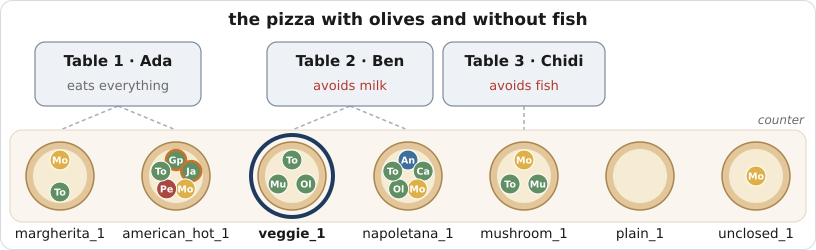

Correct! Ben gets his olives and not a single anchovy. He tips the robot.

In [13]:
pizza = the(Pizza)(toppings=a(OliveTopping)).from_(pizzas)
topping = a(PizzaTopping).from_(pizza.toppings)
olives_without_fish = pizza.where(not_(exists(topping, HasType(topping, FishTopping))))
refer("the pizza with olives and without fish", olives_without_fish, Task.OLIVES_WITHOUT_FISH)

<div style="border-left: 5px solid #8a97a8; background-color: rgba(138, 151, 168, 0.13); border-radius: 0 8px 8px 0; padding: 2px 20px; margin: 14px 0; line-height: 1.6">

**Solution note.**

`veggie_1`. In logic: `∃t (hasTopping(x, t) ∧ OliveTopping(t)) ∧ ¬∃t' (hasTopping(x, t') ∧
FishTopping(t'))`, and exactly one pizza satisfies it tonight. A good question back names a property that
one candidate has and the other has not.

If the robot still asks back, you wrote the condition on `topping` without a quantifier:
`pizza.where(not_(HasType(topping, FishTopping)))`. An unquantified variable means *some*, so that query
asks for a pizza with *at least one* topping that is not fish, `∃t (hasTopping(x, t) ∧ ¬FishTopping(t))`,
which `napoletana_1` has too.

</div>

<hr style="border: 0; border-top: 4px solid #4a7fb5; margin: 28px 0 0">

## Act 2 · Defining: *"Which pizzas may carry the green V?"*

The chef prints tomorrow's menu, where a green **V** marks a vegetarian pizza. A supplier has also just
delivered two frozen pizzas. In Act 1 you *asked* which pizzas are vegetarian; now the word gets a
meaning of its own. A **definition** gives a description a name, and the name is then used to check a
candidate, to classify every pizza, and to conclude from the label alone.

### 2(a) A class declaration already says part of what a thing is

A Python object keeps the class it was created with: `veggie_1` cannot *become* a `VegetarianPizza`. A
label that an existing object takes on is a **role**: an object of its own that stands for the pizza
(its *role taker*) and reads every attribute through to it. `Role[Pizza]` declares such a class.

In [14]:
@dataclass(eq=False, repr=False)
class MenuLabel(Role[Pizza]):
    def __repr__(self):
        return f"{type(self).__name__}({self.role_taker})"

class VegetarianPizza(MenuLabel): ...
class VeganPizza(VegetarianPizza): ...
class MeatyPizza(MenuLabel): ...


def read_declarations(*classes):
    # Print what KRROOD reads from the class declarations: superclasses, typed attributes, roles.
    diagram = ClassDiagram(list(classes))
    for relation in diagram.inheritance_relations:
        print(f"every {relation.target.clazz.__name__} is a {relation.source.clazz.__name__}")
    roles = [relation.source.clazz for relation in diagram.associations if isinstance(relation, HasRoleTaker)]
    for relation in diagram.associations:
        source, target = relation.source.clazz, relation.target.clazz.__name__
        attribute = relation.wrapped_field.field.name
        if isinstance(relation, HasRoleTaker):
            if not any(other is not source and issubclass(source, other) for other in roles):
                print(f"every {source.__name__} is a role of one {target}")
        elif attribute in inspect.get_annotations(source):
            if relation.wrapped_field.is_iterable:
                print(f"every {source.__name__} has {attribute}, each a {target}")
            else:
                print(f"every {source.__name__} has a {attribute}, which is a {target}")


read_declarations(PizzaTopping, CheeseTopping, MozzarellaTopping, Pizza, Order, Guest,
                  MenuLabel, VegetarianPizza, VeganPizza)

every CheeseTopping is a PizzaTopping
every MozzarellaTopping is a CheeseTopping
every VegetarianPizza is a MenuLabel
every VeganPizza is a VegetarianPizza
every Pizza has toppings, each a PizzaTopping
every Order has a guest, which is a Guest
every Order has pizzas, each a Pizza
every MenuLabel is a role of one Pizza


<div style="border-left: 5px solid #4a7fb5; background-color: rgba(74, 127, 181, 0.13); border-radius: 0 8px 8px 0; padding: 2px 20px; margin: 14px 0; line-height: 1.6">

**Your turn · logic.** On the worksheet, write each printed line as a first-order formula. Which of them
could ever make an object a `Pizza`, or a `VegetarianPizza`?

</div>

<div style="border-left: 5px solid #4f9a6b; background-color: rgba(79, 154, 107, 0.13); border-radius: 0 8px 8px 0; padding: 2px 20px; margin: 14px 0; line-height: 1.6">

<details>
<summary><b>Check your result</b> (open it after running the cell)</summary>

**8 formulas**, one per printed line.

</details>

</div>

<div style="border-left: 5px solid #8a97a8; background-color: rgba(138, 151, 168, 0.13); border-radius: 0 8px 8px 0; padding: 2px 20px; margin: 14px 0; line-height: 1.6">

**Solution note.**

- `every MozzarellaTopping is a CheeseTopping`: `∀x (MozzarellaTopping(x) → CheeseTopping(x))`.
- `every Pizza has toppings, each a PizzaTopping`: `∀x ∀t (Pizza(x) ∧ hasTopping(x, t) → PizzaTopping(t))`.
- `every Order has a guest, which is a Guest`: `∀o (Order(o) → Guest(guest(o)))`; `guest` is a function.
- `every MenuLabel is a role of one Pizza`: `∀l (MenuLabel(l) → Pizza(roleTaker(l)))`.

All of them are **necessary** conditions: they say what follows *from* being a C, never when something
*is* a C. None can make an object a pizza. In Python the class is asserted when the object is created,
and `HasType` is `isinstance`: it reads the asserted class, it never infers one. These were the subclass
and range axioms of `pizza.owl`. Python does not check type hints at run time; KRROOD and EQL read them.

</div>

### 2(b) A definition is necessary *and* sufficient

The menu's rule:

> A pizza is vegetarian **if and only if** it has no meat topping and no fish topping.
>
> `∀x (VegetarianPizza(x) ↔ Pizza(x) ∧ ¬∃t (hasTopping(x, t) ∧ (MeatTopping(t) ∨ FishTopping(t))))`

Read from right to left, the condition is *sufficient*: whatever satisfies it is vegetarian. Read from
left to right, it is *necessary*: whatever is vegetarian satisfies it. In EQL the right-hand side is a
condition on one pizza variable, the vegetarian query of Act 1 with a name.

<div style="border-left: 5px solid #c38d2c; background-color: rgba(195, 141, 44, 0.14); border-radius: 0 8px 8px 0; padding: 2px 20px; margin: 14px 0; line-height: 1.6">

**Predict** whether the robot accepts `frozen_1` (mozzarella, ham) and `frozen_2` (tomato, capers) for
the green V, then run the cell.

</div>

frozen_1 rejected
frozen_2 accepted


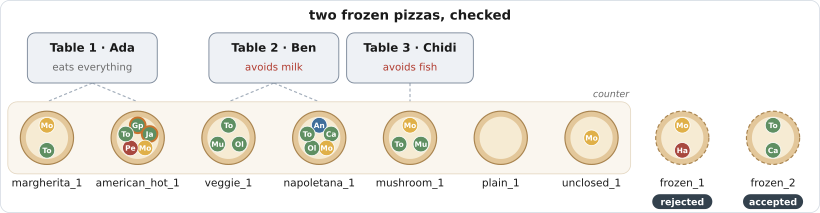

In [15]:
def has_topping(pizza, *kinds):
    # The condition that the pizza has a topping of one of these classes: ∃t (hasTopping(x, t) ∧ ...).
    topping = a(PizzaTopping).from_(pizza.toppings)
    if len(kinds) == 1:
        return exists(topping, HasType(topping, kinds[0]))
    return exists(topping, or_(*(HasType(topping, kind) for kind in kinds)))


def is_vegetarian_pizza(pizza):
    # The definition of VegetarianPizza: a condition on one pizza variable.
    return not_(has_topping(pizza, MeatTopping, FishTopping))


def accepts(definition, candidate):
    # Check one candidate: is the definition true of it?
    pizza = a(Pizza).from_([candidate])
    return bool(pizza.where(definition(pizza)).tolist())


frozen_1 = Pizza("frozen_1", [MozzarellaTopping(), HamTopping()])
frozen_2 = Pizza("frozen_2", [TomatoTopping(), CaperTopping()])
verdicts = [(candidate, "accepted" if accepts(is_vegetarian_pizza, candidate) else "rejected")
            for candidate in (frozen_1, frozen_2)]
for candidate, verdict in verdicts:
    print(candidate, verdict)
picture(notes=verdicts, more_pizzas=[frozen_1, frozen_2], title="two frozen pizzas, checked")

Checking a candidate asks about *one* given object. **Classifying** asks it of every pizza and writes the
answer down: the sufficient direction becomes a rule, `∀x (φ(x) → VegetarianPizza(x))`, and
`inference(VegetarianPizza)(role_taker=...)` gives every pizza that fits the role.

[VegetarianPizza(margherita_1), VegetarianPizza(mushroom_1), VegetarianPizza(veggie_1), VegetarianPizza(plain_1), VegetarianPizza(unclosed_1)]
the role reads through to its pizza: [MozzarellaTopping, TomatoTopping]


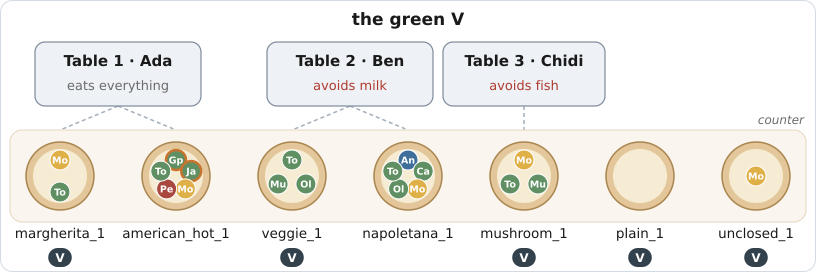

In [16]:
pizza = a(Pizza).from_(pizzas)
vegetarian_pizzas = inference(VegetarianPizza)(role_taker=pizza.where(is_vegetarian_pizza(pizza))).tolist()
print(vegetarian_pizzas)
print("the role reads through to its pizza:", vegetarian_pizzas[0].toppings)
picture(notes=[(label.role_taker, "V") for label in vegetarian_pizzas], title="the green V")

<div style="border-left: 5px solid #8a97a8; background-color: rgba(138, 151, 168, 0.13); border-radius: 0 8px 8px 0; padding: 2px 20px; margin: 14px 0; line-height: 1.6">

**Solution note.**

`frozen_1` is rejected (ham), `frozen_2` accepted. Checking a candidate is the formula with its variable
bound, `φ(a)`: a question with the answer yes or no. Classifying gives the role to `margherita_1`,
`mushroom_1`, `veggie_1`, `plain_1` and `unclosed_1`. A role is a Python object of its own, but it stands
for the same pizza: the rule adds a fact about something that exists, not a new thing in the kitchen.

</div>

#### Registry or domain?

The classification above looked only at `.from_(pizzas)`, tonight's counter. The same question can be put
to the registry, by leaving `.from_` out.

<div style="border-left: 5px solid #c38d2c; background-color: rgba(195, 141, 44, 0.14); border-radius: 0 8px 8px 0; padding: 2px 20px; margin: 14px 0; line-height: 1.6">

**Predict** whether the two answers differ, then run the cell.

</div>

vegetarian, in the registry: 6 answer(s)
    veggie_1
    plain_1
    unclosed_1
    frozen_2
    margherita_1
    mushroom_1


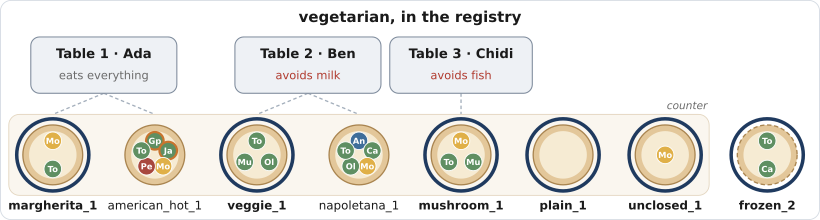

vegetarian, on the counter: 5 answer(s)
    margherita_1
    mushroom_1
    veggie_1
    plain_1
    unclosed_1


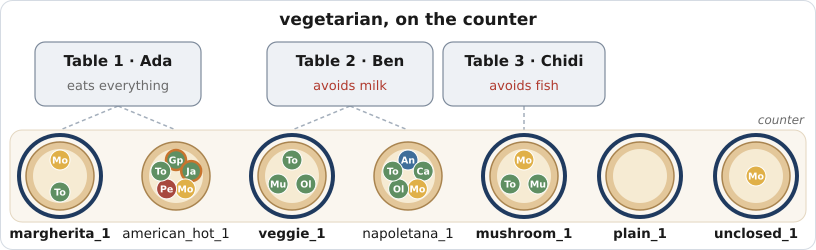

In [17]:
pizza = a(Pizza)
show("vegetarian, in the registry", pizza.where(is_vegetarian_pizza(pizza)))
pizza = a(Pizza).from_(pizzas)
show("vegetarian, on the counter", pizza.where(is_vegetarian_pizza(pizza)))

<div style="border-left: 5px solid #8a97a8; background-color: rgba(138, 151, 168, 0.13); border-radius: 0 8px 8px 0; padding: 2px 20px; margin: 14px 0; line-height: 1.6">

**Solution note.**

The registry also returns `frozen_2`. Creating the frozen pizzas to check them entered them in the
registry, but they are not on tonight's menu. The registry is everything the robot has ever created;
`.from_(...)` is the domain the question is about. `accepts` puts the domain into words as
`.from_([candidate])`: a check is about one object, and nothing else should answer it.

</div>

**Think** (on the worksheet). A pizza from the other branch arrives with a green V; nobody wrote down its
toppings. What may the robot tell Chidi, who avoids fish? And Ben, who avoids milk?

<div style="border-left: 5px solid #8a97a8; background-color: rgba(138, 151, 168, 0.13); border-radius: 0 8px 8px 0; padding: 2px 20px; margin: 14px 0; line-height: 1.6">

**Solution note.**

Chidi: it is safe, by the *necessary* direction. `VegetarianPizza(x) → ¬∃t (hasTopping(x, t) ∧
FishTopping(t))` follows from the name alone, without looking at the pizza. Ben: nothing, because the
definition says nothing about cheese. No query of Act 1 could answer this, since the toppings are
unknown. A definition is used in both directions: ← to classify, → to conclude from the class.

</div>

### 2(c) Rules with exceptions

The menu gets more labels. The chef's rule of thumb:

> A pizza without meat and fish is **vegetarian**, *unless* it has no cheese either: then it is
> **vegan**. *Otherwise*, if it has meat, it is **meaty**.

A rule tree states exactly this. `deduced_variable(MenuLabel)` stands for the conclusion; inside
`with rules:`, the first `add` is the default conclusion, `refinement(condition)` is the *unless* (it
replaces the conclusion where its condition also holds), and `alternative(condition)` is the *otherwise*
(tried where the first condition fails). The declaration `class VeganPizza(VegetarianPizza)` of 2(a)
already says that every vegan pizza is vegetarian.

<div style="border-left: 5px solid #c38d2c; background-color: rgba(195, 141, 44, 0.14); border-radius: 0 8px 8px 0; padding: 2px 20px; margin: 14px 0; line-height: 1.6">

**Predict** the label of each pizza on the worksheet, then run the cell.

</div>

[VegetarianPizza(margherita_1), MeatyPizza(american_hot_1), VegetarianPizza(mushroom_1), VeganPizza(veggie_1), VeganPizza(plain_1), VegetarianPizza(unclosed_1)]


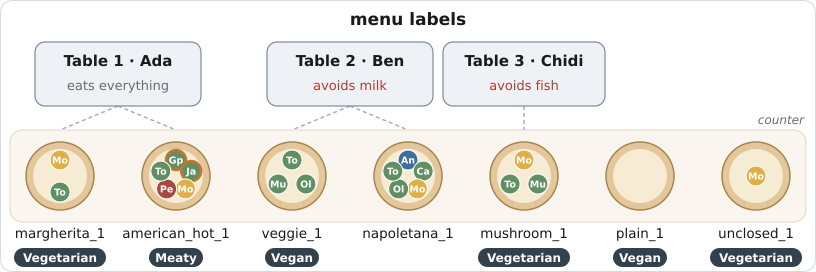

In [18]:
def label_pizzas():
    pizza = a(Pizza).from_(pizzas)
    label = deduced_variable(MenuLabel)
    rules = entity(label).where(is_vegetarian_pizza(pizza))
    with rules:
        add(label, inference(VegetarianPizza)(role_taker=pizza))
        with refinement(not_(has_topping(pizza, CheeseTopping))):
            add(label, inference(VeganPizza)(role_taker=pizza))
        with alternative(has_topping(pizza, MeatTopping)):
            add(label, inference(MeatyPizza)(role_taker=pizza))
    return rules.tolist()


labels = label_pizzas()
print(labels)
picture(notes=[(label.role_taker, type(label).__name__.removesuffix("Pizza")) for label in labels], title="menu labels")

<div style="border-left: 5px solid #8a97a8; background-color: rgba(138, 151, 168, 0.13); border-radius: 0 8px 8px 0; padding: 2px 20px; margin: 14px 0; line-height: 1.6">

**Solution note.**

Vegetarian: `margherita_1`, `mushroom_1`, `unclosed_1`. Vegan: `veggie_1`, `plain_1`. Meaty:
`american_hot_1`. **No label:** `napoletana_1` has fish, so the first condition fails, and no meat, so the
alternative fails as well. The rules are *silent* about it. Silence is not "no": they never concluded
"not vegetarian". The refinement is an *exception*: a more specific conclusion replaces the general one.
Trees of this shape are known as ripple-down rules.

</div>

<hr style="border: 0; border-top: 4px solid #4a7fb5; margin: 28px 0 0">

## Act 3 · Constraining: *"Ben must never get milk."*

Ben avoids milk. Nothing in the knowledge base says *"napoletana_1 contains milk"*. It has to be computed:
mozzarella is a cheese, cheese contains milk, the pizza has that topping.

### 3(a) Knowledge as a function

`symbolic_function` turns a Python function into vocabulary of the query language. Called on an object,
it returns its value; called on a variable, it becomes a condition that is evaluated for every candidate.

on an object:  True
on a variable: InstantiatedVariable - a piece of a query, not a truth value
vegetarian, with last week's function: 5 answer(s)
    margherita_1
    mushroom_1
    veggie_1
    plain_1
    unclosed_1


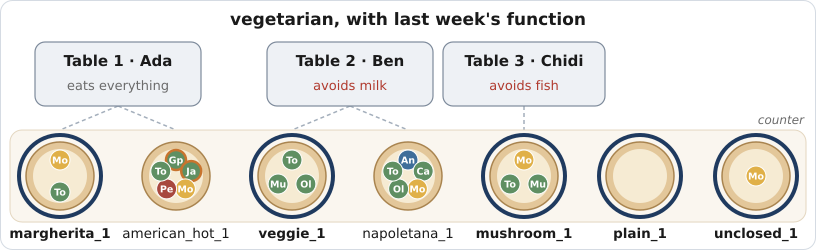

In [19]:
is_vegetarian = symbolic_function(is_vegetarian)

pizza = a(Pizza).from_(pizzas)
print("on an object: ", is_vegetarian(margherita_1))
print("on a variable:", type(is_vegetarian(pizza)).__name__, "- a piece of a query, not a truth value")
show("vegetarian, with last week's function", pizza.where(is_vegetarian(pizza)))

<div style="border-left: 5px solid #4a7fb5; background-color: rgba(74, 127, 181, 0.13); border-radius: 0 8px 8px 0; padding: 2px 20px; margin: 14px 0; line-height: 1.6">

**Your turn · Python.** Complete `allergens`: a pizza with a cheese topping contains `Allergen.MILK`, a
pizza with a fish topping contains `Allergen.FISH`. Every pizza contains gluten, because of its base.
Inside the function, `pizza` is a real `Pizza` object, not a query: write ordinary Python, with
`pizza.toppings`, `isinstance` and `any`, and no `a(...)`, `HasType` or `.where`. `symbolic_function` makes
it usable in queries afterwards.

</div>

margherita_1     ['gluten', 'milk']
napoletana_1     ['fish', 'gluten', 'milk']
american_hot_1   ['gluten', 'milk']
mushroom_1       ['gluten', 'milk']
veggie_1         ['gluten']
plain_1          ['gluten']
unclosed_1       ['gluten', 'milk']


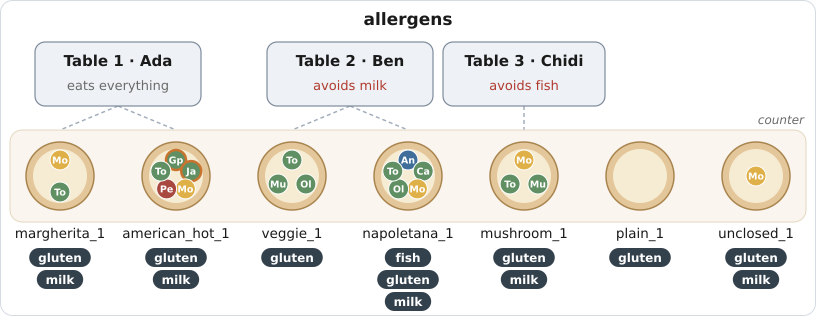

Correct! Every allergen is on the menu. The health inspector nods, which never happens.

In [20]:
@symbolic_function
def allergens(pizza: Pizza) -> set[Allergen]:
    found = {Allergen.GLUTEN}
    if any(isinstance(topping, CheeseTopping) for topping in pizza.toppings):
        found.add(Allergen.MILK)
    if any(isinstance(topping, FishTopping) for topping in pizza.toppings):
        found.add(Allergen.FISH)
    return found


for each_pizza in pizzas:
    print(f"{each_pizza.name:16}", sorted(allergen.value for allergen in allergens(each_pizza)))
picture(notes=[(each_pizza, allergen.value) for each_pizza in pizzas
               for allergen in sorted(allergens(each_pizza), key=lambda allergen: allergen.value)],
        title="allergens")
grade(Task.ALLERGENS, [f"{each_pizza}: {allergen.value}" for each_pizza in pizzas
                       for allergen in allergens(each_pizza)])

### 3(b) A computed relation

`hasTopping` is *stored*: it is the list `toppings`. *"Pizza x is safe for guest g"* is a relation as well,
but stored nowhere: it is computed from both. A `Predicate` is such a relation. Its fields are its
arguments, `__call__` decides whether it holds, and `_verbalization_fragment_` tells EQL how to say it in
English.

<div style="border-left: 5px solid #4a7fb5; background-color: rgba(74, 127, 181, 0.13); border-radius: 0 8px 8px 0; padding: 2px 20px; margin: 14px 0; line-height: 1.6">

**Your turn · Python.** Complete `__call__`: a pizza is safe for a guest if it contains none of the
allergens the guest avoids. It runs on real objects: `self.pizza` is a `Pizza` and `self.guest` a `Guest`,
so write ordinary Python that returns `True` or `False`. `allergens` from 3(a) works here too, and gives
a `set`.

</div>

The query below the class is given. It uses *one* variable `pizza` twice: in `.where` and as the
argument of the predicate. Writing `a(Pizza)` a second time would introduce a second, unrelated pizza.

what can Ben eat?: 2 answer(s)
    veggie_1
    plain_1


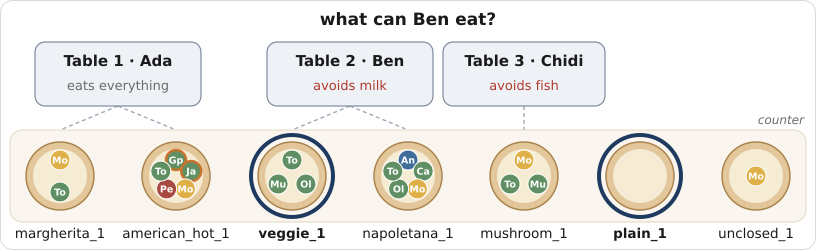

Correct! Ben eats well and stays out of hospital.

In [21]:
@dataclass(eq=False)
class IsSafeFor(Predicate):
    pizza: Pizza
    guest: Guest

    def __call__(self) -> bool:
        return not (allergens(self.pizza) & self.guest.avoids)

    @classmethod
    def _verbalization_fragment_(cls, fields):   # how EQL says it in English; do not edit
        return clause(Noun(fields["pizza"]), Copula(), Adjective("safe"), Prepositions.FOR, Noun(fields["guest"]))


pizza = a(Pizza).from_(pizzas)
show("what can Ben eat?", pizza.where(IsSafeFor(pizza, ben)), Task.SAFE_FOR_BEN)

### 3(c) A constraint is a query that must have no answer

That was a *question*. The kitchen also has a *rule that must never be broken*:

> Every pizza of an order is safe for the guest of that order:
> `∀o ∀x (hasPizza(o, x) → IsSafeFor(x, guest(o)))`

Its negation is `∃o ∃x (hasPizza(o, x) ∧ ¬IsSafeFor(x, guest(o)))`. The constraint holds exactly when this
query has **no** answer, and if it has one, the answer names the culprit.

<div style="border-left: 5px solid #4a7fb5; background-color: rgba(74, 127, 181, 0.13); border-radius: 0 8px 8px 0; padding: 2px 20px; margin: 14px 0; line-height: 1.6">

**Your turn · EQL.** Write `dangerous`: the pairs of an order and one of its pizzas that is not safe for the
guest of that order. **Predict** the answer first.

</div>

every pizza is safe for its guest: VIOLATED by (Order(table 2), napoletana_1)


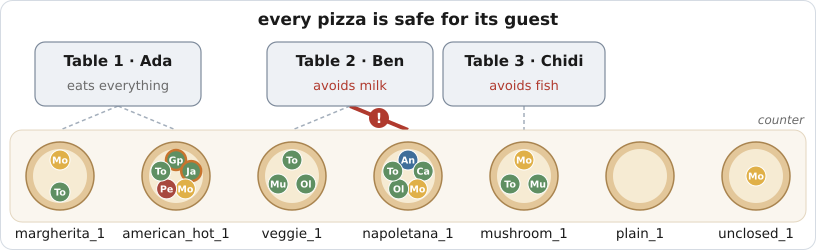

Correct! The robot stops exactly the one dangerous plate. Nobody goes to hospital tonight.

In [22]:
order = an(Order).from_(orders)
pizza = a(Pizza).from_(order.pizzas)
dangerous = set_of(order, pizza).where(not_(IsSafeFor(pizza, order.guest)))
check("every pizza is safe for its guest", dangerous, Task.DANGEROUS_PLATES)

<div style="border-left: 5px solid #8a97a8; background-color: rgba(138, 151, 168, 0.13); border-radius: 0 8px 8px 0; padding: 2px 20px; margin: 14px 0; line-height: 1.6">

**Solution note.**

One violation: table 2, Ben, `napoletana_1` (mozzarella, hence milk). The query does not only say *that*
the constraint is broken; the binding says *where*, so the robot knows which plate not to serve.
`order.guest` follows a relation from the order to its guest, like the term `guest(o)` in the formula.

</div>

<hr style="border: 0; border-top: 4px solid #4a7fb5; margin: 28px 0 0">

## Act 4 · Deriving: *the kitchen writes allergen warnings*

### 4(a) A rule creates objects

The predicate of Act 3 computes its answer every time it is asked. A **rule** writes its conclusion down
once, for later queries to use. The labels of Act 2 were such conclusions about pizzas that exist. An
allergen warning is different: a slip of paper on the pizza, a *new* object.
`inference(AllergenWarning)(pizza=..., allergen=...)` creates one warning for every pizza that fits the
description given for `pizza`: the description is the body of the rule, the new warning its head.

> `∀x (Pizza(x) ∧ ∃t (hasTopping(x, t) ∧ CheeseTopping(t)) → ∃w (Warning(w) ∧ about(w, x) ∧ allergen(w) = milk))`

<div style="border-left: 5px solid #4a7fb5; background-color: rgba(74, 127, 181, 0.13); border-radius: 0 8px 8px 0; padding: 2px 20px; margin: 14px 0; line-height: 1.6">

**Your turn · EQL.** The milk rule is given. Write the rule for fish, and the rule that *every* pizza carries a
gluten warning (its body is just `a(Pizza).from_(pizzas)`). **Predict** the number of warnings.

</div>

13 warnings


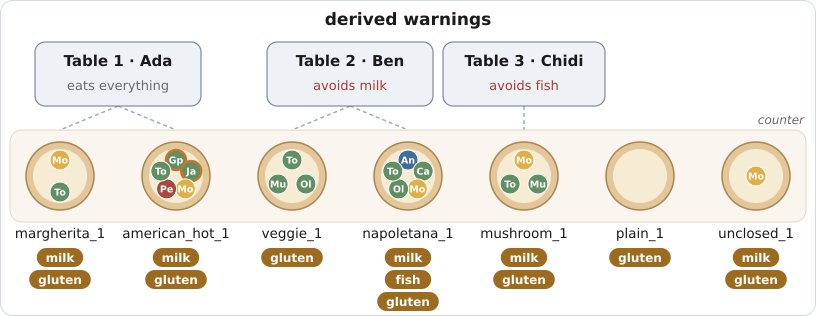

Correct! Every slip of paper is right. The pizzeria's insurance lowers its rate.

In [23]:
@dataclass(eq=False, repr=False)
class AllergenWarning:
    pizza: Pizza
    allergen: Allergen

    def __repr__(self):
        return f"Warning({self.pizza}: {self.allergen.value})"


milk_warnings = inference(AllergenWarning)(pizza=cheesy, allergen=Allergen.MILK).tolist()

fishy = a(Pizza)(toppings=a(FishTopping)).from_(pizzas)
fish_warnings = inference(AllergenWarning)(pizza=fishy, allergen=Allergen.FISH).tolist()
gluten_warnings = inference(AllergenWarning)(pizza=a(Pizza).from_(pizzas), allergen=Allergen.GLUTEN).tolist()

warnings = milk_warnings + fish_warnings + gluten_warnings
print(len(warnings), "warnings")
picture(warnings=[(warning.pizza, warning.allergen.value) for warning in warnings], title="derived warnings")
grade(Task.ALLERGEN_WARNINGS, warnings)

<div style="border-left: 5px solid #8a97a8; background-color: rgba(138, 151, 168, 0.13); border-radius: 0 8px 8px 0; padding: 2px 20px; margin: 14px 0; line-height: 1.6">

**Solution note.**

13 warnings: 5 milk, 1 fish, 7 gluten. The head `∃w` is why new objects appear: for every answer of the
body, the rule creates a witness. The label rule of Act 2 had no `∃` in its head, `∀x (φ(x) →
VegetarianPizza(x))`, and only added facts about the pizzas there are. Deriving all conclusions in advance
is *forward chaining* (materialisation); deriving a conclusion only when a question needs it, as the
predicate of Act 3 does, is the strategy of *backward chaining*.

</div>

### 4(b) The world moves on

It is busy. The cook mixes up two tickets and grates parmesan over `veggie_1`, Ben's pizza.

<div style="border-left: 5px solid #c38d2c; background-color: rgba(195, 141, 44, 0.14); border-radius: 0 8px 8px 0; padding: 2px 20px; margin: 14px 0; line-height: 1.6">

**Predict** what each of the three outputs says, then run the cell. Which of them protects Ben?

</div>

1. the constraint of Act 3, evaluated now: VIOLATED by (Order(table 2), veggie_1)
1. the constraint of Act 3, evaluated now: VIOLATED by (Order(table 2), napoletana_1)


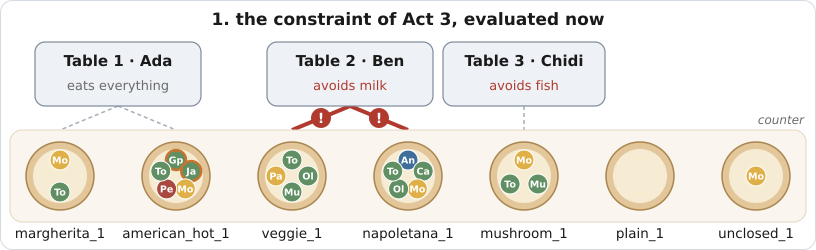

2. the milk warnings derived in 4(a): [Warning(margherita_1: milk), Warning(napoletana_1: milk), Warning(american_hot_1: milk), Warning(mushroom_1: milk), Warning(unclosed_1: milk)]


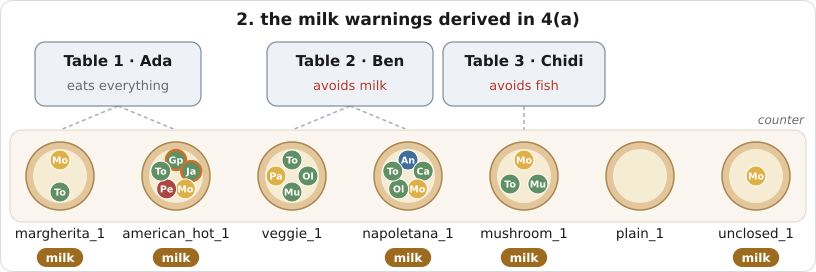

3. the label of veggie_1, derived again: [VegetarianPizza(veggie_1)]


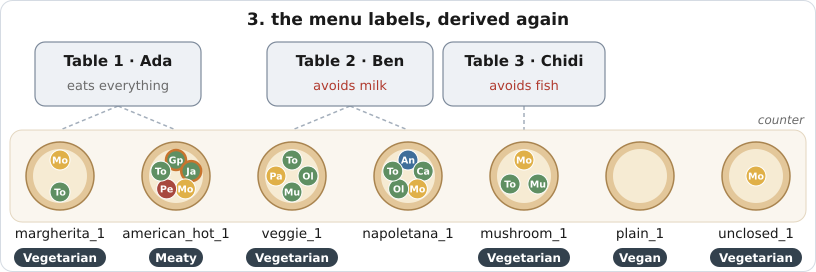

In [24]:
# The cook adds ParmesanTopping to the three toppings veggie_1 had.
veggie_1.toppings = [TomatoTopping(), OliveTopping(), MushroomTopping(), ParmesanTopping()]

check("1. the constraint of Act 3, evaluated now", dangerous)

print("2. the milk warnings derived in 4(a):", milk_warnings)
picture(warnings=[(warning.pizza, warning.allergen.value) for warning in milk_warnings],
        title="2. the milk warnings derived in 4(a)")

labels_now = label_pizzas()
print("3. the label of veggie_1, derived again:",
      [label for label in labels_now if label.role_taker is veggie_1])
picture(notes=[(label.role_taker, type(label).__name__.removesuffix("Pizza")) for label in labels_now],
        title="3. the menu labels, derived again")

<div style="border-left: 5px solid #8a97a8; background-color: rgba(138, 151, 168, 0.13); border-radius: 0 8px 8px 0; padding: 2px 20px; margin: 14px 0; line-height: 1.6">

**Solution note.**

1. The constraint reports **two** violations now: `napoletana_1` and `veggie_1`. It was written before the
   mistake, and it is evaluated against the world as it is at the moment it is asked.
2. The stored milk warnings do not mention `veggie_1`. They were derived at a fixed moment and are stale
   until the rule runs again. Keeping derived facts in line with their reasons is *truth maintenance*.
3. `veggie_1` was `VeganPizza`, now it is `VegetarianPizza`. A new fact *removed* a conclusion: the
   reasoning is **non-monotonic**, because the vegan rule relies on the absence of cheese. Classical
   first-order logic is monotonic: what follows from a set of formulas still follows when formulas are
   added.

</div>

the constraint, after the new veggie_1: VIOLATED by (Order(table 2), napoletana_1)


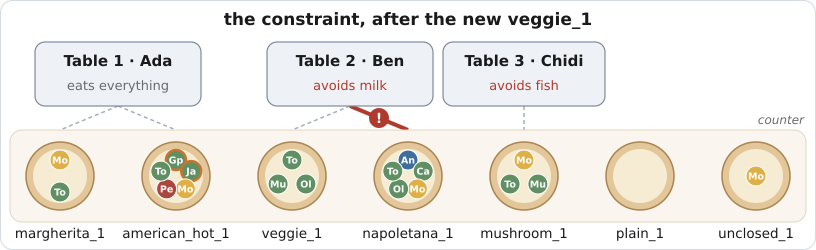

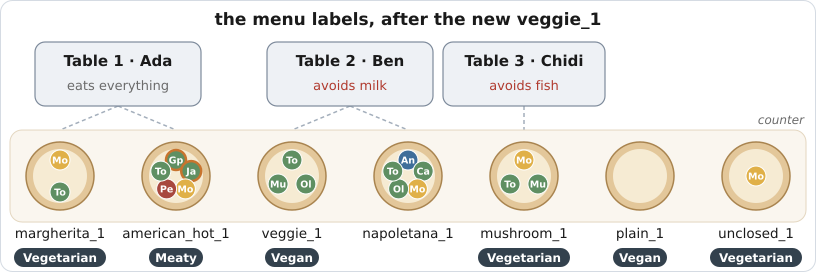

In [25]:
# The cook bakes Ben a new veggie_1: ParmesanTopping is gone, the three toppings stay.
veggie_1.toppings = [TomatoTopping(), OliveTopping(), MushroomTopping()]

check("the constraint, after the new veggie_1", dangerous)
picture(notes=[(label.role_taker, type(label).__name__.removesuffix("Pizza")) for label in label_pizzas()],
        title="the menu labels, after the new veggie_1")

<hr style="border: 0; border-top: 4px solid #4a7fb5; margin: 28px 0 0">

## Act 5 · Generating: *"A pizza with mozzarella and tomato, please."*

Dana sits down at table 4 and orders *"a pizza with mozzarella and tomato, nothing else"*. That is a
description, exactly like those of Act 1. What changes is *who answers it*. A query is a symbolic object;
a **backend** is something that answers it. The one you used so far *selects* existing objects that
fit; a generative backend *constructs* a new object that fits. Below, one and the same `wish` goes to both.

selected from the counter: [margherita_1]


made by the kitchen:       [a new pizza] [MozzarellaTopping, TomatoTopping]


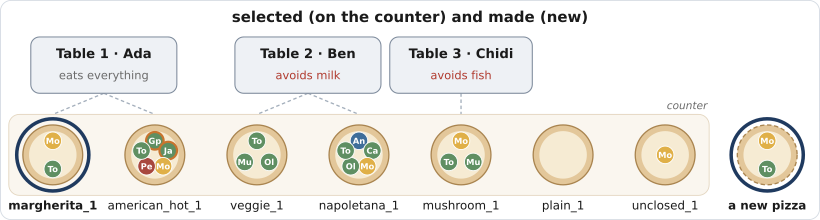

In [26]:
wish = a(Pizza)(toppings=[a(MozzarellaTopping), a(TomatoTopping)]).from_(pizzas)

on_the_counter = list(EntityQueryLanguageBackend().evaluate(wish))
print("selected from the counter:", on_the_counter)

from_the_kitchen = list(EntityQueryLanguageGenerativeBackend().evaluate(wish))
print("made by the kitchen:      ", from_the_kitchen, from_the_kitchen[0].toppings)

picture(marked=on_the_counter + from_the_kitchen, title="selected (on the counter) and made (new)")

A description usually leaves things open. Dana adds: *"and a green pepper, I don't mind how hot"*. `...`
marks what she left open.

<div style="border-left: 5px solid #c38d2c; background-color: rgba(195, 141, 44, 0.14); border-radius: 0 8px 8px 0; padding: 2px 20px; margin: 14px 0; line-height: 1.6">

**Predict:** how many pizzas does the kitchen offer?

</div>

a new pizza [(MozzarellaTopping, 'MILD'), (HotGreenPepperTopping, 'MILD')]
a new pizza [(MozzarellaTopping, 'MILD'), (HotGreenPepperTopping, 'MEDIUM')]
a new pizza [(MozzarellaTopping, 'MILD'), (HotGreenPepperTopping, 'HOT')]


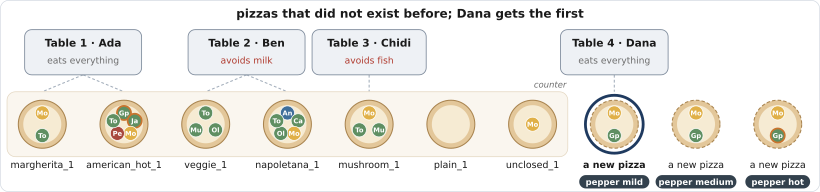

In [27]:
open_wish = a(Pizza)(toppings=[a(MozzarellaTopping), a(HotGreenPepperTopping)(spiciness=...)])

candidates = list(EntityQueryLanguageGenerativeBackend().evaluate(open_wish))
for candidate in candidates:
    print(candidate, [(topping, topping.spiciness.name) for topping in candidate.toppings])

dana = Guest("Dana")
picture(marked=candidates[:1], more_orders=[Order(4, dana, candidates[:1])], more_pizzas=candidates,
        notes=[(candidate, f"pepper {candidate.toppings[1].spiciness.name.lower()}") for candidate in candidates],
        title="pizzas that did not exist before; Dana gets the first")

<div style="border-left: 5px solid #8a97a8; background-color: rgba(138, 151, 168, 0.13); border-radius: 0 8px 8px 0; padding: 2px 20px; margin: 14px 0; line-height: 1.6">

**Solution note.**

Three pizzas, one per value of `Spiciness`: the generator fills the open slot in every possible way. In
Act 1 the description *selected* among existing objects (checking a given interpretation); here it is a
*specification*, and an answer is a new object that makes it true (constructing a model). Act 5(b) on the
worksheet goes one step further: a robot plan whose open slots are answered by different backends.

</div>

**Think** (on the worksheet). Every pizza the kitchen offered is now in the registry. Which question of
tonight would get a different answer if the robot asked it again now? The next cell asks `hot_pizzas` of
1(c) again.

7 pizzas on the counter, 13 pizzas in the registry
hot pizzas, asked again: 2 answer(s)
    a new pizza
    american_hot_1


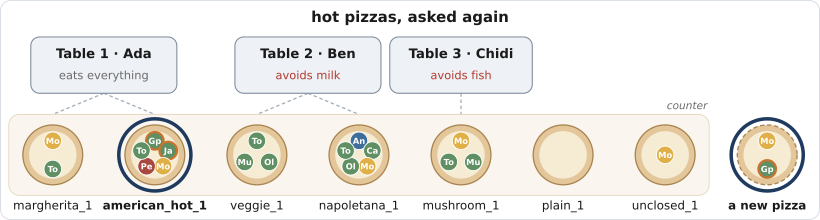

In [28]:
print(len(pizzas), "pizzas on the counter,", len(a(Pizza).tolist()), "pizzas in the registry")
show("hot pizzas, asked again", hot_pizzas)

<div style="border-left: 5px solid #8a97a8; background-color: rgba(138, 151, 168, 0.13); border-radius: 0 8px 8px 0; padding: 2px 20px; margin: 14px 0; line-height: 1.6">

**Solution note.**

`hot_pizzas` has no `.from_`, and every evaluation reads the registry as it is then: asked again, it also
finds the kitchen's offer whose green pepper is hot, a pizza nobody ordered. So would the vegetarian
question asked of the registry in 2(b).
Every question with `.from_(pizzas)` or `.from_(orders)` keeps its answer. Ask the registry when the
question is about everything the robot knows; give a domain when it is about a particular set, such
as tonight's counter or one candidate.

</div>

<hr style="border: 0; border-top: 4px solid #4a7fb5; margin: 28px 0 0">

## The whole picture

Everything the robot found out tonight, in one picture: the answers to the chef's question (Act 1), the
menu labels (Act 2), the violated constraint (Act 3) and the warnings (Act 4).

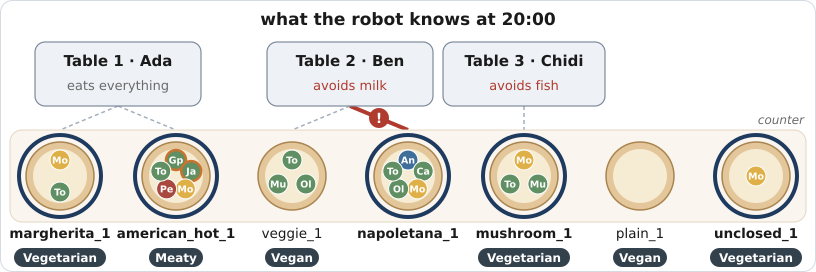

In [29]:
violations = [] if dangerous is ... else [(order, pizza) for order, pizza in rows_of(dangerous)]
picture(marked=cheesy.tolist(), violations=violations,
        notes=[(label.role_taker, type(label).__name__.removesuffix("Pizza")) for label in label_pizzas()],
        title="what the robot knows at 20:00")

<hr style="border: 0; border-top: 4px solid #4a7fb5; margin: 28px 0 0">

## The bill

Every wrong answer tonight cost the pizzeria a fine: hospital bills, lost guests, a lawyer. Here is the
total. It keeps every fine since you first ran the notebook, even across restarts, and a wrong answer
costs only once. Compare it with your neighbours: the lowest bill wins.

In [30]:
display(checker.bill())

The bill of the evening: €0. Not a single fine; the pizzeria's insurance sends flowers.